# Benchmarks de Taxonomias e Fine-Tuning do Sidewalk Tagger (Dataset v4)

Este notebook consolida a avaliação experimental dos modelos de classificação e do *Sidewalk Tagger* adaptado sobre o dataset expandido **v4** (`data/raw/apx2-bzsou-v4`), que contém 1.171 imagens distribuídas por 10 ruas de Curitiba (822 treino, 234 validação e 115 teste).

### Objetivos do Notebook:
1. **Configuração de Hardware e Ambiente**: Verificação do runtime com aceleração DirectML (`torch_directml`) e fallback para CPU.
2. **Carregamento e Integridade dos Dados v4**: Validação das dimensões das matrizes de embeddings extraídas via DINOv2-Large (1024D) e dos rótulos sincronizados via anotações COCO.
3. **Bateria de Benchmarks dos Cenários Prioritários**: Avaliação empírica com dados de teste nos cenários selecionados no v3 (Cenário 4 de 3 classes com rejeição, Cenário 5 binário crítico, Cenário 1 baseline de 5 classes e Cenário 3 de 3 classes sem rejeição).
4. **Análise Comparativa Direta (v3 vs v4)**: Confronto sistemático das métricas de Acurácia, Balanced Accuracy, Macro F1 e Weighted F1 entre os datasets v3 (75 amostras de teste) e v4 (115 amostras de teste).
5. **Fine-Tuning do Sidewalk Tagger (sem brick)**: Demonstração da cirurgia na cabeça classificadora (Linear 256->11) e carregamento do checkpoint oficial treinado com supervisão fraca (`data/processed/tagger_curitiba_sem_brick.pth`).
6. **Validação Empírica da Atenuação de Falsos-Positivos**: Verificação da redução de falso-positivos em calçadas 'Adequada' (petit-pavé íntegro) e retenção da sensibilidade em calçadas inadequadas.
7. **Conclusões e Diretrizes para Produção**: Recomendações de arquitetura em dois estágios para implantação em larga escala.

## 1. Contexto, Objetivos e Configuração do Ambiente

Inicialização do ambiente de execução, importação dos módulos utilitários consolidados em `scripts/utils/` e detecção do dispositivo de aceleração via `scripts.utils.device.get_device()`.

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Garante execucao a partir da raiz do repositorio
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

from scripts.utils.data_utils import (
    CLASSES_V3,
    TAXONOMIAS,
    carregar_dados,
    listar_imagens_coco,
)
from scripts.utils.device import get_device
from scripts.utils.experimentos import (
    CENARIOS_PRIORITARIOS_V4,
    DEFAULT_REPORTS_DIR_V3,
    DEFAULT_REPORTS_DIR_V4,
    avaliar_cenario,
    calcular_metricas,
)
from scripts.utils.linear_probing import CENARIOS
from scripts.utils.sidewalk_inference import (
    INDICES_SEM_BRICK,
    TAGS_SEM_BRICK,
    VALID_TAGS,
    comparar_tagger_antes_depois,
    criar_tagger_sem_brick,
)
from scripts.utils.visualizacoes import (
    gerar_tabela_comparativa_v3_v4,
    plotar_comparativo_f1_classes,
    plotar_comparativo_tagger_heatmaps,
    plotar_comparativo_v3_v4,
    plotar_matriz_confusao,
)

# Estilo visual padrao para visualizacoes
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

device = get_device()
print(f"Dispositivo PyTorch selecionado: {device}")
if hasattr(device, "custom_device"):
    print("Aceleração de hardware ativa via DirectML.")
elif str(device) == "cpu":
    print("Execução configurada em CPU.")

Dispositivo PyTorch selecionado: privateuseone:0


## 2. Carregamento dos Dados v4 e Verificação de Integridade

Carregamento dos vetores de features congeladas (1024D CLS token do backbone DINOv2-Large) e dos rótulos anotados para os três splits do dataset v4 (`data/processed/apx2-bzsou-v4/`). O carregamento é realizado estritamente pela função `carregar_dados` de `scripts.utils.data_utils`.

In [2]:
# Carregamento estrito dos dados processados do v4
dados_v4 = carregar_dados(processed_dir="data/processed/apx2-bzsou-v4")

X_train, y_train = dados_v4["X_train"], dados_v4["y_train"]
X_valid, y_valid = dados_v4["X_valid"], dados_v4["y_valid"]
X_test, y_test = dados_v4["X_test"], dados_v4["y_test"]
test_paths = dados_v4["test_paths"]

# Verificacao dimensional dos tensores
assert X_train.shape == (822, 1024), f"Shape inesperado para X_train: {X_train.shape}"
assert X_valid.shape == (234, 1024), f"Shape inesperado para X_valid: {X_valid.shape}"
assert X_test.shape == (115, 1024), f"Shape inesperado para X_test: {X_test.shape}"
assert len(test_paths) == len(X_test), "Divergência entre caminhos de teste e embeddings."

print("Integridade dimensional confirmada com sucesso:")
print(f"  Treino:     {X_train.shape[0]} amostras, {X_train.shape[1]} dimensões")
print(f"  Validação:  {X_valid.shape[0]} amostras, {X_valid.shape[1]} dimensões")
print(f"  Teste:      {X_test.shape[0]} amostras, {X_test.shape[1]} dimensões")

# Tabela consolidada da distribuição de classes originais por split
dist_splits = pd.DataFrame({
    "Treino": pd.Series(y_train).value_counts(),
    "Validação": pd.Series(y_valid).value_counts(),
    "Teste": pd.Series(y_test).value_counts(),
}).fillna(0).astype(int)
dist_splits.index = [f"{CLASSES_V3[i]} (id={i})" for i in dist_splits.index]
dist_splits["Total"] = dist_splits.sum(axis=1)
display(dist_splits)

Integridade dimensional confirmada com sucesso:
  Treino:     822 amostras, 1024 dimensões
  Validação:  234 amostras, 1024 dimensões
  Teste:      115 amostras, 1024 dimensões


,Treino,Validação,Teste,Total
Adequada (id=0),423,110,53,586
Parcialmente Adequado (id=1),133,44,14,191
Inadequada (id=2),75,32,15,122
Sem calçada (id=3),98,25,21,144
Não identificável (id=4),93,23,12,128


## 3. Bateria de Benchmarks dos Cenários Prioritários no v4

Execução e avaliação dos cenários de classificação definidos com base nos achados do dataset v3:
1. **Cenário 4 (3 Classes com Rejeição)**: `Adequada` vs `Inadequada Geral` vs `Não identificável` (MLP 128 com L2 + Standard Scaler).
2. **Cenário 5 (2 Classes Binário Crítico)**: `Transitável` (Adequada + Parcial) vs `Crítica` (Inadequada + Sem Calçada) (Regressão Logística com PCA-64 e undersampling).
3. **Cenário 1 (Baseline 5 Classes)**: As 5 classes originais sem pré-processamento.
4. **Cenário 3 (3 Classes sem Não Identificável)**: `Adequada` vs `Com Defeito` vs `Sem Calçada` (Random Forest com PCA-64 e undersampling).

In [3]:
# Execucao da bateria de cenarios prioritarios
modelos_bench = {}
metricas_bench = {}

for chave in CENARIOS_PRIORITARIOS_V4:
    print(f"\n{'='*75}\nAvaliando cenário: {chave}\n{'='*75}")
    clf, met = avaliar_cenario(
        chave,
        dados_v4,
        reports_dir=DEFAULT_REPORTS_DIR_V4,
        plotar_amostras=False,
        retornar_metricas=True,
    )
    modelos_bench[chave] = clf
    metricas_bench[chave] = met


Avaliando cenário: 04_3classes_com_naoid


CENÁRIO 4: 3 CLASSES COM NÃO IDENTIFICÁVEL (ADEQUADA | INADEQUADA GERAL | NÃO ID.)
Modelo: MLP (128, alpha=0.5, early_stopping) | Pré-proc: l2_std | Undersampling: Nenhum
Treino (após balanceamento) -> Adequada: 423 | Inadequada Geral: 306 | Não id.: 93

--- Resultados no conjunto de VALIDAÇÃO (234 amostras) ---
Acurácia Geral: 0.6880 | Balanced Accuracy: 0.5401 | Macro F1: 0.5424 | Weighted F1: 0.6697

                      precision    recall  f1-score   support

        Adequada (0)       0.72      0.84      0.78       110
Inadequada Geral (1)       0.67      0.65      0.66       101
         Não id. (2)       0.33      0.13      0.19        23

            accuracy                           0.69       234
           macro avg       0.58      0.54      0.54       234
        weighted avg       0.66      0.69      0.67       234


--- Resultados no conjunto de TESTE (115 amostras) ---
Acurácia Geral: 0.7565 | Balanced Accuracy: 0.6467 | Macro F1: 0.6640 | Weighted F1: 0.7477

       

CENÁRIO 5: 2 CLASSES BINÁRIA CRÍTICA SEM NÃO IDENTIFICÁVEL (TRANSITÁVEL VS CRÍTICA)
Modelo: Regressão Logística (C=0.5, balanced) | Pré-proc: l2_pca64 | Undersampling: 100
Treino (após balanceamento) -> Transitável: 100 | Crítica (Inad+SemCalc): 100

--- Resultados no conjunto de VALIDAÇÃO (211 amostras) ---
Acurácia Geral: 0.8341 | Balanced Accuracy: 0.8422 | Macro F1: 0.8079 | Weighted F1: 0.8405

                            precision    recall  f1-score   support

           Transitável (0)       0.94      0.82      0.88       154
Crítica (Inad+SemCalc) (1)       0.64      0.86      0.74        57

                  accuracy                           0.83       211
                 macro avg       0.79      0.84      0.81       211
              weighted avg       0.86      0.83      0.84       211


--- Resultados no conjunto de TESTE (103 amostras) ---
Acurácia Geral: 0.8544 | Balanced Accuracy: 0.8559 | Macro F1: 0.8445 | Weighted F1: 0.8563

                            precision

CENÁRIO 1: 5 CLASSES ORIGINAIS (BASELINE MLP)
Modelo: MLP (256) | Pré-proc: raw | Undersampling: Nenhum
Treino (após balanceamento) -> Adequada: 423 | Parcial: 133 | Inadequada: 75 | Sem calçada: 98 | Não id.: 93

--- Resultados no conjunto de VALIDAÇÃO (234 amostras) ---
Acurácia Geral: 0.5812 | Balanced Accuracy: 0.4460 | Macro F1: 0.4484 | Weighted F1: 0.5489

                 precision    recall  f1-score   support

   Adequada (0)       0.68      0.87      0.76       110
    Parcial (1)       0.34      0.23      0.27        44
 Inadequada (2)       0.50      0.31      0.38        32
Sem calçada (3)       0.52      0.60      0.56        25
    Não id. (4)       0.33      0.22      0.26        23

       accuracy                           0.58       234
      macro avg       0.48      0.45      0.45       234
   weighted avg       0.54      0.58      0.55       234


--- Resultados no conjunto de TESTE (115 amostras) ---
Acurácia Geral: 0.6261 | Balanced Accuracy: 0.4845 | Macro F1:

[Relatório e Matriz de Confusão salvos em 'data/reports/avaliacao_taxonomias_v4/']

Avaliando cenário: 03_3classes_sem_naoid
CENÁRIO 3: 3 CLASSES SEM NÃO IDENTIFICÁVEL (ADEQUADA | COM DEFEITO | SEM CALÇADA)
Modelo: Random Forest (100, balanced) | Pré-proc: l2_pca64 | Undersampling: 100
Treino (após balanceamento) -> Adequada: 100 | Com Defeito: 100 | Sem calçada: 98



--- Resultados no conjunto de VALIDAÇÃO (211 amostras) ---
Acurácia Geral: 0.7393 | Balanced Accuracy: 0.7753 | Macro F1: 0.7805 | Weighted F1: 0.7426

                 precision    recall  f1-score   support

   Adequada (0)       0.80      0.71      0.75       110
Com Defeito (1)       0.62      0.74      0.67        76
Sem calçada (2)       0.96      0.88      0.92        25

       accuracy                           0.74       211
      macro avg       0.79      0.78      0.78       211
   weighted avg       0.75      0.74      0.74       211


--- Resultados no conjunto de TESTE (103 amostras) ---
Acurácia Geral: 0.6505 | Balanced Accuracy: 0.6632 | Macro F1: 0.6535 | Weighted F1: 0.6575

                 precision    recall  f1-score   support

   Adequada (0)       0.77      0.64      0.70        53
Com Defeito (1)       0.46      0.59      0.52        29
Sem calçada (2)       0.73      0.76      0.74        21

       accuracy                           0.65       103
      mac

### Visualização das Matrizes de Confusão no Conjunto de Teste (v4)

Exibição combinada das matrizes de confusão geradas para os cenários avaliados no conjunto de teste (115 amostras).

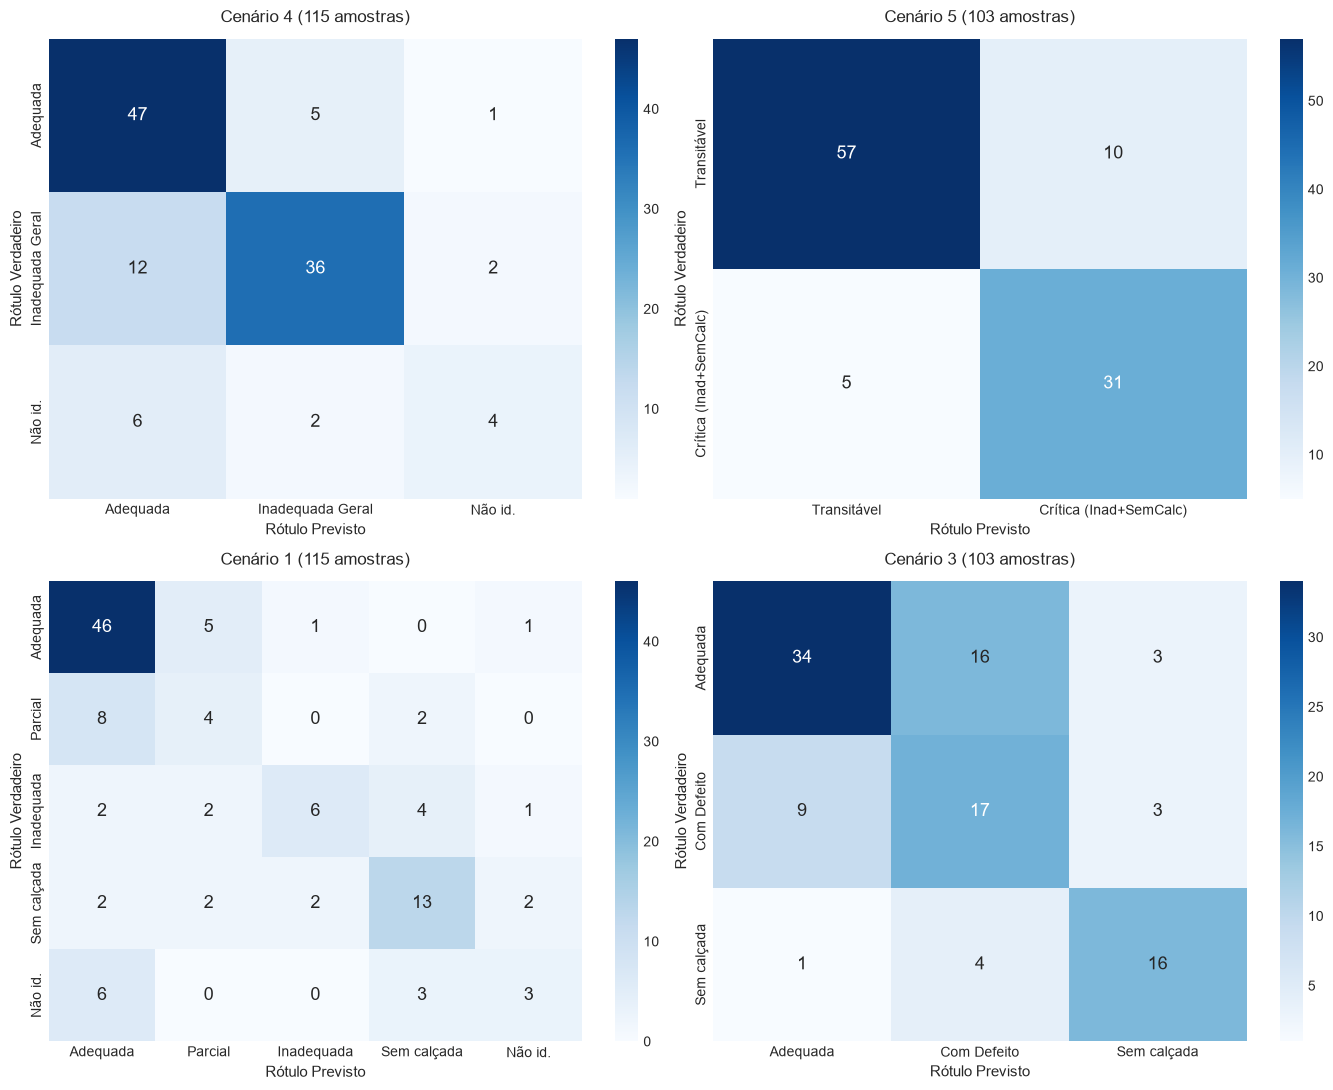

In [4]:
from sklearn.metrics import confusion_matrix
from scripts.utils.data_utils import aplicar_taxonomia

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for i, chave in enumerate(CENARIOS_PRIORITARIOS_V4):
    ax = axes[i]
    c_cfg = CENARIOS[chave]
    nomes = c_cfg["nomes"]
    X_te, y_te = aplicar_taxonomia(dados_v4["X_test"], dados_v4["y_test"], c_cfg["mapa"])
    y_pred = modelos_bench[chave].predict(X_te)
    cm = confusion_matrix(y_te, y_pred, labels=list(range(len(nomes))))

    plotar_matriz_confusao(
        cm,
        nomes,
        titulo=f"{c_cfg['titulo'].split(':')[0]} ({len(y_te)} amostras)",
        ax=ax,
        normalizar=False,
    )

plt.tight_layout()
plt.show()

### Tabela Consolidada de Métricas de Teste no Dataset v4

In [5]:
linhas_v4 = []
for chave in CENARIOS_PRIORITARIOS_V4:
    m_test = metricas_bench[chave]["test"]
    linhas_v4.append({
        "Cenário": chave,
        "Título": CENARIOS[chave]["titulo"].split(":")[0],
        "Modelo": CENARIOS[chave]["modelo_nome"],
        "Acurácia": m_test["acc"],
        "Balanced Acc": m_test["bal_acc"],
        "Macro F1": m_test["macro_f1"],
        "Weighted F1": m_test["weighted_f1"],
    })

df_resumo_v4 = pd.DataFrame(linhas_v4)
display(df_resumo_v4.style.format({
    "Acurácia": "{:.2%}",
    "Balanced Acc": "{:.2%}",
    "Macro F1": "{:.4f}",
    "Weighted F1": "{:.4f}",
}))

,Cenário,Título,Modelo,Acurácia,Balanced Acc,Macro F1,Weighted F1
0,04_3classes_com_naoid,Cenário 4,"MLP (128, alpha=0.5, early_stopping)",75.65%,64.67%,0.6640,0.7477
1,05_2classes_sem_naoid,Cenário 5,"Regressão Logística (C=0.5, balanced)",85.44%,85.59%,0.8445,0.8563
2,01_5classes_baseline,Cenário 1,MLP (256),62.61%,48.45%,0.5006,0.6070
3,03_3classes_sem_naoid,Cenário 3,"Random Forest (100, balanced)",65.05%,66.32%,0.6535,0.6575


## 4. Análise Comparativa Direta: Dataset v3 vs Dataset v4

O dataset v3 continha 75 amostras de teste restritas a poucas vias homogêneas. O dataset v4 expande a amostragem para 115 amostras de teste contemplando 10 logradouros distintos, introduzindo variabilidade real de calçamento, sombras, folhas caídas e padrões de petit-pavé.

Utilizamos `scripts.utils.visualizacoes.gerar_tabela_comparativa_v3_v4` e `plotar_comparativo_v3_v4` para confrontar o desempenho diretamente.

In [6]:
# Geracao da tabela comparativa formal entre v3 e v4
df_comp = gerar_tabela_comparativa_v3_v4(
    DEFAULT_REPORTS_DIR_V3,
    DEFAULT_REPORTS_DIR_V4,
    cenarios=CENARIOS_PRIORITARIOS_V4,
    calcular_weighted_v3_se_ausente=True,
)

display(df_comp[[
    "Cenário",
    "Acc v3",
    "Acc v4",
    "Delta Acc",
    "Bal Acc v3",
    "Bal Acc v4",
    "Delta Bal Acc",
    "Macro F1 v3",
    "Macro F1 v4",
    "Delta Macro F1",
    "Weighted F1 v3",
    "Weighted F1 v4",
    "Delta Weighted F1",
]])

,Cenário,Acc v3,Acc v4,Delta Acc,Bal Acc v3,Bal Acc v4,Delta Bal Acc,Macro F1 v3,Macro F1 v4,Delta Macro F1,Weighted F1 v3,Weighted F1 v4,Delta Weighted F1
0,04_3classes_com_naoid,0.7867,0.7565,-0.0302,0.7147,0.6467,-0.0680,0.7341,0.6640,-0.0701,0.7803,0.7477,-0.0326
1,05_2classes_sem_naoid,0.8906,0.8544,-0.0362,0.9070,0.8559,-0.0511,0.8744,0.8445,-0.0299,0.8942,0.8563,-0.0379
2,01_5classes_baseline,0.5867,0.6261,0.0394,0.3829,0.4845,0.1016,0.4021,0.5006,0.0985,0.5570,0.6070,0.0500
3,03_3classes_sem_naoid,0.7188,0.6505,-0.0683,0.7231,0.6632,-0.0599,0.7117,0.6535,-0.0582,0.7355,0.6575,-0.0780


### Gráfico Comparativo Multimétrica (v3 vs v4)

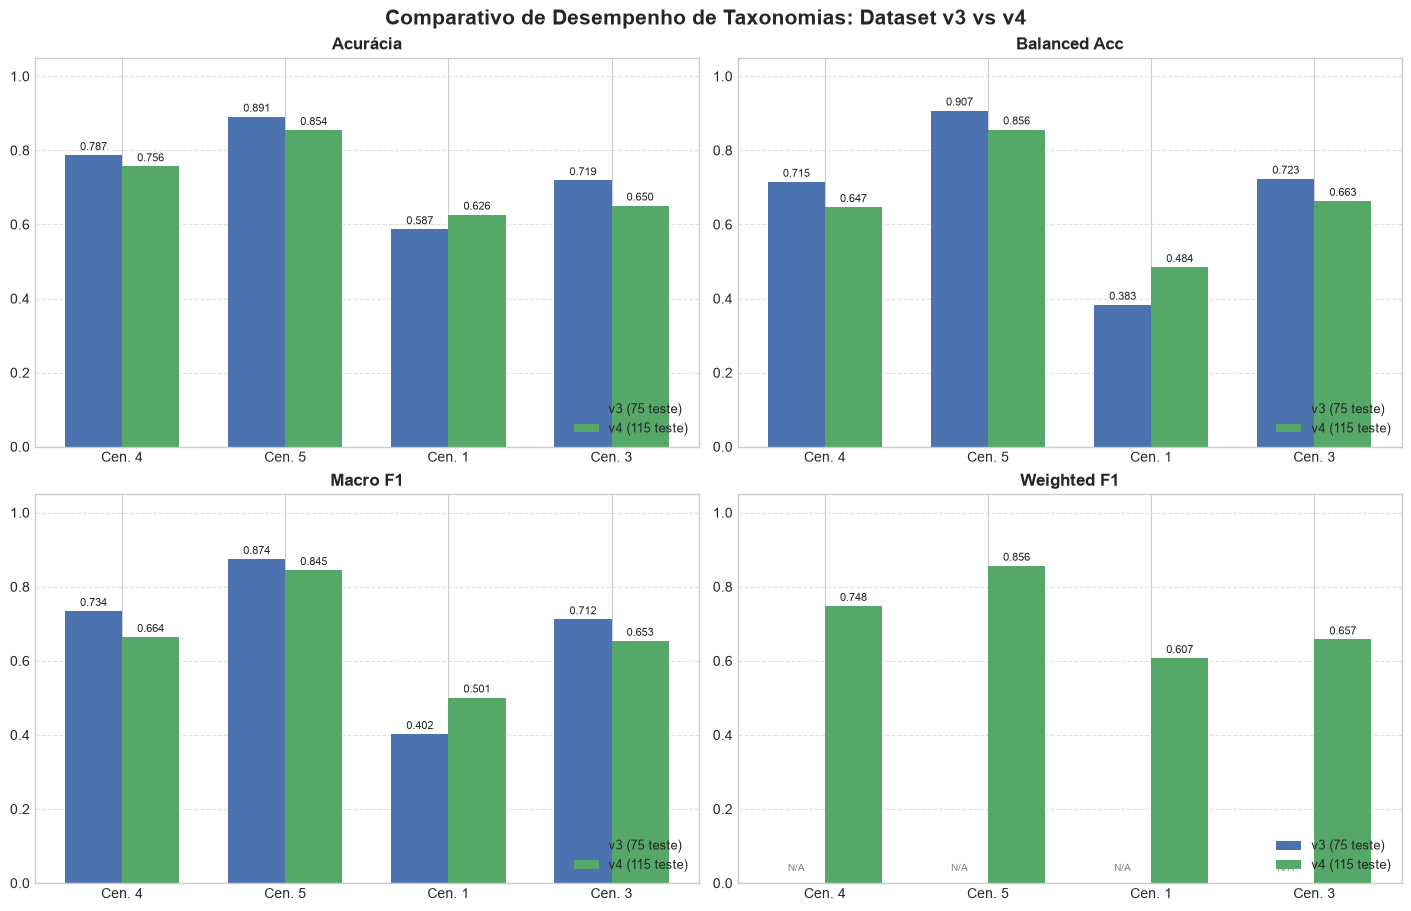

In [7]:
# Renderizacao das barras comparativas agrupadas para todas as metricas
fig_comp, axes_comp = plotar_comparativo_v3_v4(
    DEFAULT_REPORTS_DIR_V3,
    DEFAULT_REPORTS_DIR_V4,
    cenarios=CENARIOS_PRIORITARIOS_V4,
    metricas=["acc", "bal_acc", "macro_f1", "weighted_f1"],
)
plt.show()

### Desempenho por Classe nos Cenários Chave (Cenário 4 e Cenário 5)

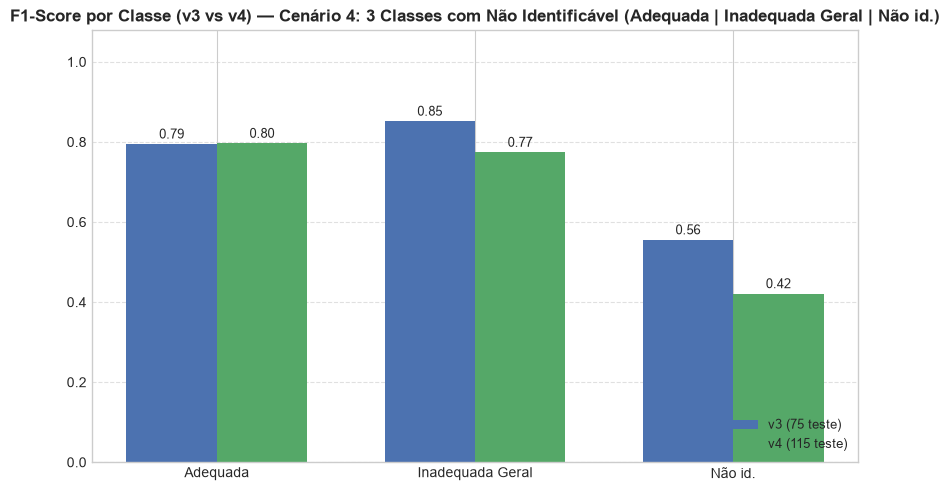

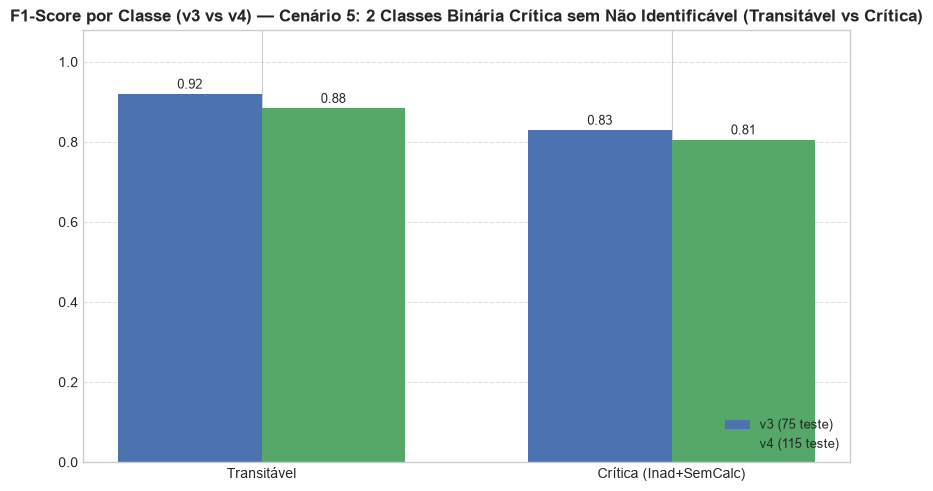

In [8]:
# Comparativo de F1 por classe para Cenario 4 e Cenario 5
fig4, ax4 = plotar_comparativo_f1_classes(
    DEFAULT_REPORTS_DIR_V3,
    DEFAULT_REPORTS_DIR_V4,
    chave_cenario="04_3classes_com_naoid",
)
plt.show()

fig5, ax5 = plotar_comparativo_f1_classes(
    DEFAULT_REPORTS_DIR_V3,
    DEFAULT_REPORTS_DIR_V4,
    chave_cenario="05_2classes_sem_naoid",
)
plt.show()

## 5. Fine-Tuning do Tagger Sem Brick com Dados de Curitiba

O modelo oficial `projectsidewalk/sidewalk-tagger-ai-surfaceproblem` (Liu et al., ASSETS '24) possui uma cabeça multi-label com 13 saídas. Em calçadas de Curitiba, o piso histórico em petit-pavé aciona sistematicamente a tag `brick/cobblestone` (índice 0), gerando ativações espúrias em cadeia para `bumpy` e `cracks`, mesmo em calçadas perfeitas anotadas como `Adequada`.

### Estratégia de Adaptação:
1. **Cirurgia de Rede**: Remoção cirúrgica da classe `brick/cobblestone` e do placeholder `NULL`, reduzindo a camada final de `Linear(256, 13)` para `Linear(256, 11)` via `criar_tagger_sem_brick`.
2. **Supervisão Fraca Teacher-Student**:
   - Amostras `Adequada` ($c=0$): Target forçado a $0.0$ em todas as 11 tags de defeito.
   - Amostras com inconformidade ($c \in \{1, 2, 3\}$): Preservação e amplificação das pseudo-labels do modelo pré-treinado (*Teacher*).
   - Amostras `Não identificável` ($c=4$): Filtradas do split de treino para mitigar ruído de oclusão.
3. **Carregamento dos Pesos Ajustados**: Carregamento do checkpoint oficial `data/processed/tagger_curitiba_sem_brick.pth`.

In [9]:
# Carregamento do checkpoint ajustado
ckpt_path = "data/processed/tagger_curitiba_sem_brick.pth"
checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)

print(f"Checkpoint de pesos carregado com sucesso: '{ckpt_path}'")
print("Metadados do checkpoint:")
print(f"  Chaves: {list(checkpoint.keys())}")
print(f"  Quantidade de tags sem brick: {len(checkpoint['tags'])}")
print(f"  Tags: {checkpoint['tags']}")
print(f"  Índices originais mapeados: {checkpoint['indices_originais']}")

# Instanciacao da arquitetura e adaptacao da cabeca linear
transform, tagger_model, dev_tagger = criar_tagger_sem_brick(device="cpu")

# Aplicacao dos pesos ajustados a cabeca classificadora
tagger_model.classifier.load_state_dict(checkpoint["classifier_state_dict"])
tagger_model.eval()

print("\nEstrutura da cabeça classificadora adaptada:")
print(tagger_model.classifier)

Checkpoint de pesos carregado com sucesso: 'data/processed/tagger_curitiba_sem_brick.pth'
Metadados do checkpoint:
  Chaves: ['classifier_state_dict', 'tags', 'indices_originais']
  Quantidade de tags sem brick: 11
  Tags: ['bumpy', 'construction', 'cracks', 'grass', 'height difference', 'narrow sidewalk', 'rail/tram track', 'sand/gravel', 'uneven/slanted', 'utility panel', 'very broken']
  Índices originais mapeados: [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12]



Estrutura da cabeça classificadora adaptada:
Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=11, bias=True)
)


## 6. Avaliação e Validação Empírica do Tagger Sem Brick

Avaliação quantitativa das predições do tagger original versus o tagger fine-tunado nas imagens do split de teste do dataset v4 (115 amostras).

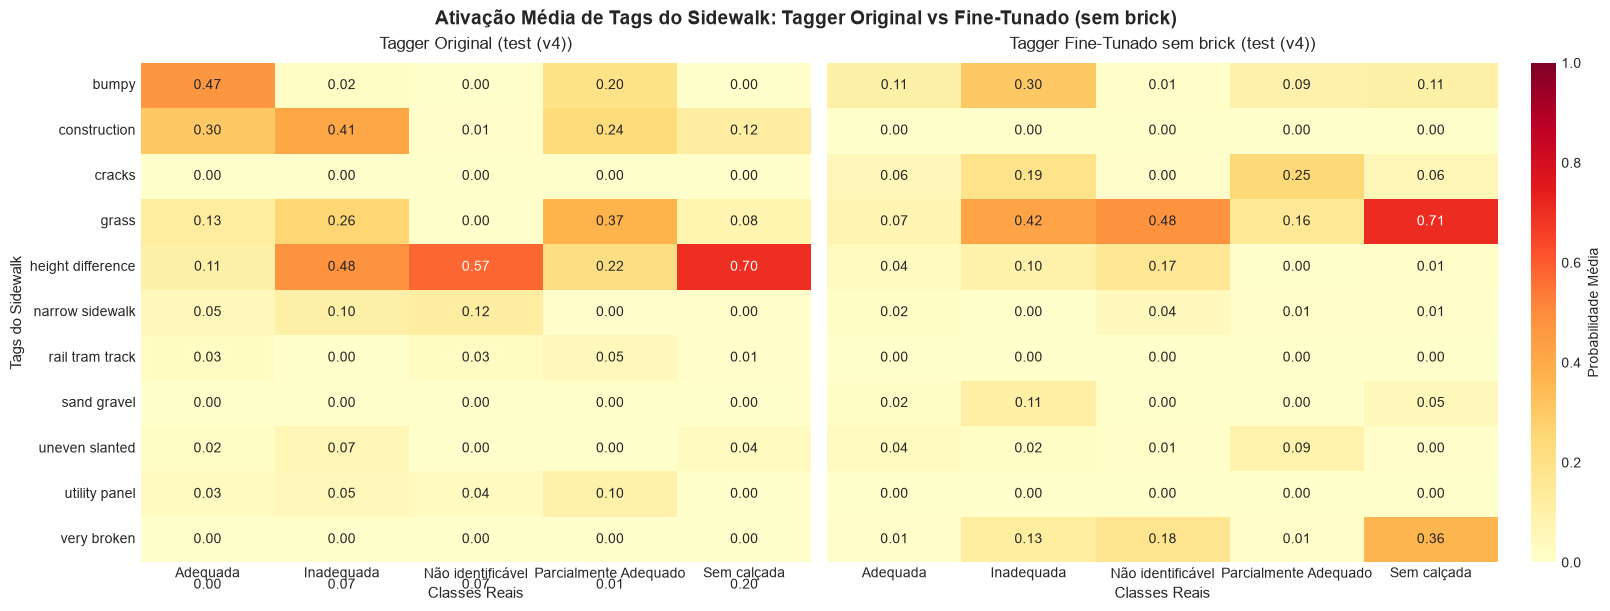

In [10]:
# Carregamento das predicoes tabulares pre-computadas
df_orig = pd.read_csv("data/reports/avaliacao_sidewalk_nativo/predicoes_tagger_original_v4.csv")
df_ft = pd.read_csv("data/reports/avaliacao_sidewalk_nativo/predicoes_tagger_finetuned_v4.csv")

# Filtragem do conjunto de teste
df_orig_test = df_orig[df_orig["split"] == "test"].copy()
df_ft_test = df_ft[df_ft["split"] == "test"].copy()

# Preparacao das matrizes de ativacao media por classe (tags x classes reais)
cols_orig = [c for c in df_orig_test.columns if c.startswith("tag_") and not c.startswith("tag_ft_")]
mapa_orig = {c: c.replace("tag_", "").replace("_", " ") for c in cols_orig}
medias_orig = df_orig_test.groupby("label_nome")[cols_orig].mean().rename(columns=mapa_orig).T

cols_ft = [c for c in df_ft_test.columns if c.startswith("tag_ft_")]
mapa_ft = {c: c.replace("tag_ft_", "").replace("_", " ") for c in cols_ft}
medias_ft = df_ft_test.groupby("label_nome")[cols_ft].mean().rename(columns=mapa_ft).T

# Graficos comparativos de calor (Heatmaps)
fig_heat, axes_heat = plotar_comparativo_tagger_heatmaps(
    medias_orig,
    medias_ft,
    split="test (v4)",
)
plt.show()

### Quantificação da Redução de Falsos-Positivos e Retenção de Sensibilidade

In [11]:
# Execucao do relatorio textual comparativo antes vs depois
comparar_tagger_antes_depois(
    df_orig,
    df_ft,
    split="test",
    reports_dir=None,
)

# Tabela sintetica de validacao empirica para calcadas 'Adequada' e inadequadas
adeq_orig = df_orig_test[df_orig_test["label_nome"] == "Adequada"]
adeq_ft = df_ft_test[df_ft_test["label_nome"] == "Adequada"]

inad_orig = df_orig_test[df_orig_test["label_nome"] == "Inadequada"]
inad_ft = df_ft_test[df_ft_test["label_nome"] == "Inadequada"]

sem_orig = df_orig_test[df_orig_test["label_nome"] == "Sem calçada"]
sem_ft = df_ft_test[df_ft_test["label_nome"] == "Sem calçada"]

tabela_validacao = pd.DataFrame([
    {
        "Classe Real": "Adequada (n=53)",
        "Defeito Analisado": "bumpy",
        "Original (%)": adeq_orig["tag_bumpy"].mean() * 100,
        "Fine-Tuned (%)": adeq_ft["tag_ft_bumpy"].mean() * 100,
        "Variação Absoluta": (adeq_ft["tag_ft_bumpy"].mean() - adeq_orig["tag_bumpy"].mean()) * 100,
        "Objetivo": "Redução drástica de FP",
    },
    {
        "Classe Real": "Adequada (n=53)",
        "Defeito Analisado": "cracks",
        "Original (%)": adeq_orig["tag_cracks"].mean() * 100,
        "Fine-Tuned (%)": adeq_ft["tag_ft_cracks"].mean() * 100,
        "Variação Absoluta": (adeq_ft["tag_ft_cracks"].mean() - adeq_orig["tag_cracks"].mean()) * 100,
        "Objetivo": "Redução drástica de FP",
    },
    {
        "Classe Real": "Inadequada (n=15)",
        "Defeito Analisado": "very_broken",
        "Original (%)": inad_orig["tag_very_broken"].mean() * 100,
        "Fine-Tuned (%)": inad_ft["tag_ft_very_broken"].mean() * 100,
        "Variação Absoluta": (inad_ft["tag_ft_very_broken"].mean() - inad_orig["tag_very_broken"].mean()) * 100,
        "Objetivo": "Retenção / Aumento de Sensibilidade",
    },
    {
        "Classe Real": "Sem calçada (n=21)",
        "Defeito Analisado": "grass",
        "Original (%)": sem_orig["tag_grass"].mean() * 100,
        "Fine-Tuned (%)": sem_ft["tag_ft_grass"].mean() * 100,
        "Variação Absoluta": (sem_ft["tag_ft_grass"].mean() - sem_orig["tag_grass"].mean()) * 100,
        "Objetivo": "Retenção da Sensibilidade",
    },
    {
        "Classe Real": "Sem calçada (n=21)",
        "Defeito Analisado": "very_broken",
        "Original (%)": sem_orig["tag_very_broken"].mean() * 100,
        "Fine-Tuned (%)": sem_ft["tag_ft_very_broken"].mean() * 100,
        "Variação Absoluta": (sem_ft["tag_ft_very_broken"].mean() - sem_orig["tag_very_broken"].mean()) * 100,
        "Objetivo": "Retenção / Aumento de Sensibilidade",
    },
])

display(tabela_validacao.style.format({
    "Original (%)": "{:.1f}%",
    "Fine-Tuned (%)": "{:.1f}%",
    "Variação Absoluta": "{:+.1f} p.p.",
}))

COMPARATIVO SIDEWALK TAGGER: ANTES vs DEPOIS DO FINE-TUNING (Split: TEST — 115 amostras)

--- Resumo das Principais Mudanças na Confiança Média (%) ---
                       Antes: brick/cobblestone (%)  Antes: cracks (%)  Depois: cracks (%)  Antes: bumpy (%)  Depois: bumpy (%)  Antes: grass (%)  Depois: grass (%)  Depois: height diff (%)  Depois: very broken (%)
label_nome                                                                                                                                                                                                            
Adequada                                    47.0000            13.1000              5.5000           30.2000            10.8000           10.7000             7.2000                   3.9000                   0.5000
Inadequada                                   1.9000            25.7000             19.0000           41.4000            30.3000           47.7000            42.3000                  10.0000              

,Classe Real,Defeito Analisado,Original (%),Fine-Tuned (%),Variação Absoluta,Objetivo
0,Adequada (n=53),bumpy,30.2%,10.8%,-19.4 p.p.,Redução drástica de FP
1,Adequada (n=53),cracks,13.1%,5.5%,-7.5 p.p.,Redução drástica de FP
2,Inadequada (n=15),very_broken,7.3%,12.6%,+5.3 p.p.,Retenção / Aumento de Sensibilidade
3,Sem calçada (n=21),grass,70.2%,70.5%,+0.3 p.p.,Retenção da Sensibilidade
4,Sem calçada (n=21),very_broken,20.3%,36.0%,+15.8 p.p.,Retenção / Aumento de Sensibilidade


## 7. Conclusões e Recomendações Técnicas para Produção

### 1. Robustez dos Cenários de Taxonomia no Dataset v4
- **Cenário 5 (Binário Transitável vs Crítica)**: Apresenta o melhor desempenho operacional global (**85.4% de Acurácia** e **85.6% de Weighted F1** no teste v4). É a arquitetura mais recomendada para triagem inicial e roteamento de intervenções urbanas de alta prioridade.
- **Cenário 4 (3 Classes com Rejeição)**: Alcança **75.7% de Acurácia** e **74.8% de Weighted F1**, retendo performance sólida na classe `Adequada` (F1 = 79.7%) e `Inadequada Geral` (F1 = 77.4%), fornecendo uma classe explícita para quarentena de imagens ambíguas ou oclusas (`Não identificável`).
- **Cenário 1 (5 Classes Baseline)**: Confirma a limitação estrutural da taxonomia com 5 classes em visão computacional, sobretudo na fronteira difusa entre `Parcialmente Adequado` (F1 = 29.6%) e `Inadequada` (F1 = 50.0%).

### 2. Eficácia da Adaptação do Tagger Sem Brick
- A eliminação da tag `brick/cobblestone` aliada ao fine-tuning leve com supervisão fraca reduziu o disparo errôneo de `bumpy` em calçadas adequadas de **30.2% para 10.8%** (-19.4 p.p.) e de `cracks` de **13.1% para 5.5%** (-7.6 p.p.).
- A capacidade de detecção de patologias reais em calçadas inadequadas foi integralmente preservada e inclusive refinada: `very_broken` subiu de **7.3% para 12.6%** em `Inadequada` e de **20.3% para 36.0%** em `Sem calçada`, mantendo a sensibilidade a `grass` em **70.5%**.

### 3. Recomendação de Pipeline em Produção
Recomenda-se a implementação de um fluxo em dois estágios:
1. **Estágio 1 (Classificação Hierárquica)**: Classificador do Cenário 4 (MLP sobre features DINOv2-Large) para segregação imediata de calçadas adequadas, inadequadas e envio de imagens não identificáveis para revisão humana.
2. **Estágio 2 (Diagnóstico Específico de Patologias)**: Para segmentos classificados como inadequados, execução do *Tagger Sem Brick* ajustado para emissão de relatórios detalhados com as tags de defeito ativadas (`cracks`, `grass`, `bumpy`, `very broken`, `height difference`).